## La Haute Borne SCADA 功率曲线清洗（bin + MAD）功能演示

数据：法国 La Haute Borne 风场 2017–2020 四台 **Senvion MM82（2.05 MW）**，列 `Ws_avg`（机舱风速 m/s）、`P_avg`（有功功率 kW）。

`PowerCurveFiltering` 一次只处理**单台风机**，多台由调用方 `groupby` 后循环调用。

`cut_in_speed` / `rated_wind_speed` / `rated_power` 是厂商机型物理参数，**必填**。厂商参数未知时，可先调用 `estimate_machine_parameters` 从 SCADA 反推（10 分钟统计口径的“软”值，额定风速比厂商标称约低 1 m/s），再显式传入。


In [5]:
import sys
sys.path.append('../')
from wtclean import DailyAnomalyDetector


import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager, rcParams

font_path = './wqy-zenhei.ttc'
font_manager.fontManager.addfont(font_path)
font_prop = font_manager.FontProperties(fname=font_path)
font_name = font_prop.get_name()
print('Loaded font name:', font_name)
rcParams['font.sans-serif'] = [font_name]
rcParams['axes.unicode_minus'] = False


Loaded font name: WenQuanYi Zen Hei


In [6]:
import pandas as pd
df = pd.read_csv('./datasets/la-haute-borne-data-2017-2020.zip', sep=';')
df['Ws_avg'] = pd.to_numeric(df['Ws_avg'], errors='coerce')
df['P_avg']  = pd.to_numeric(df['P_avg'],  errors='coerce')
df.head()

,Wind_turbine_name,Date_time,Ba_avg,Ba_min,Ba_max,Ba_std,Rt_avg,Rt_min,Rt_max,Rt_std,...,Pas_max,Pas_std,Wa_c_avg,Wa_c_min,Wa_c_max,Wa_c_std,Na_c_avg,Na_c_min,Na_c_max,Na_c_std
0,R80721,2017-02-08T08:00:00+01:00,44.990002,44.990002,44.990002,0.0,14.0,14.0,14.0,0.0,...,NaN,NaN,358.04999,NaN,NaN,NaN,358.04999,NaN,NaN,NaN
1,R80721,2017-01-26T02:40:00+01:00,-1.000000,-1.000000,-1.000000,0.0,10.0,10.0,10.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,R80721,2017-01-26T13:50:00+01:00,-1.000000,-1.000000,-1.000000,0.0,10.0,10.0,10.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,R80721,2017-01-26T15:00:00+01:00,-1.000000,-1.000000,-1.000000,0.0,10.0,10.0,10.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,R80721,2017-02-18T01:10:00+01:00,44.990002,44.990002,44.990002,0.0,17.0,17.0,17.0,0.0,...,NaN,NaN,7.99000,NaN,NaN,NaN,7.99000,NaN,NaN,NaN


### 多台清洗：循环处理四台风机（Senvion MM82）

`cut_in_speed=3.5`、`rated_wind_speed=14.5`、`rated_power=2050`（四台同型号，共用同一组厂商参数）。


In [7]:
# 厂商物理参数（Senvion MM82，四台同型号）
MACHINE = dict(cut_in_speed=3.5, rated_wind_speed=14.5, rated_power=2050)

turbines = sorted(df['Wind_turbine_name'].unique())

results = {}
for name in turbines:
    g = df[df['Wind_turbine_name'] == name]
    det = DailyAnomalyDetector(
        windspeed_label='Ws_avg',    # 风速列
        power_label='P_avg',         # 功率列
        timestamp_label='Date_time', # 时间戳列（必填）
        df=g,                        # 单台风机
        **MACHINE,
    )
    normal_df, abnormal_df = det.detect()
    results[name] = dict(det=det, normal_df=normal_df, abnormal_df=abnormal_df)
    print(f'=== {name} ===')
    print('异常天数:', len(det.abnormal_days_))
    print(det.labels_.value_counts())
    print()


=== R80711 ===
异常天数: 26
normal         44202
temporal        3648
range           3138
residual        2008
downtime         761
nan              586
curtailment       90
Name: count, dtype: int64

=== R80721 ===
异常天数: 23
normal         43492
range           4184
temporal        3297
residual        2211
downtime         818
nan              404
curtailment       27
Name: count, dtype: int64

=== R80736 ===
异常天数: 30
normal         42718
temporal        4078
range           3990
residual        1801
downtime        1367
nan              458
curtailment       21
Name: count, dtype: int64

=== R80790 ===
异常天数: 26
normal         42876
temporal        3696
range           3616
residual        2265
downtime        1610
nan              210
curtailment       16
Name: count, dtype: int64



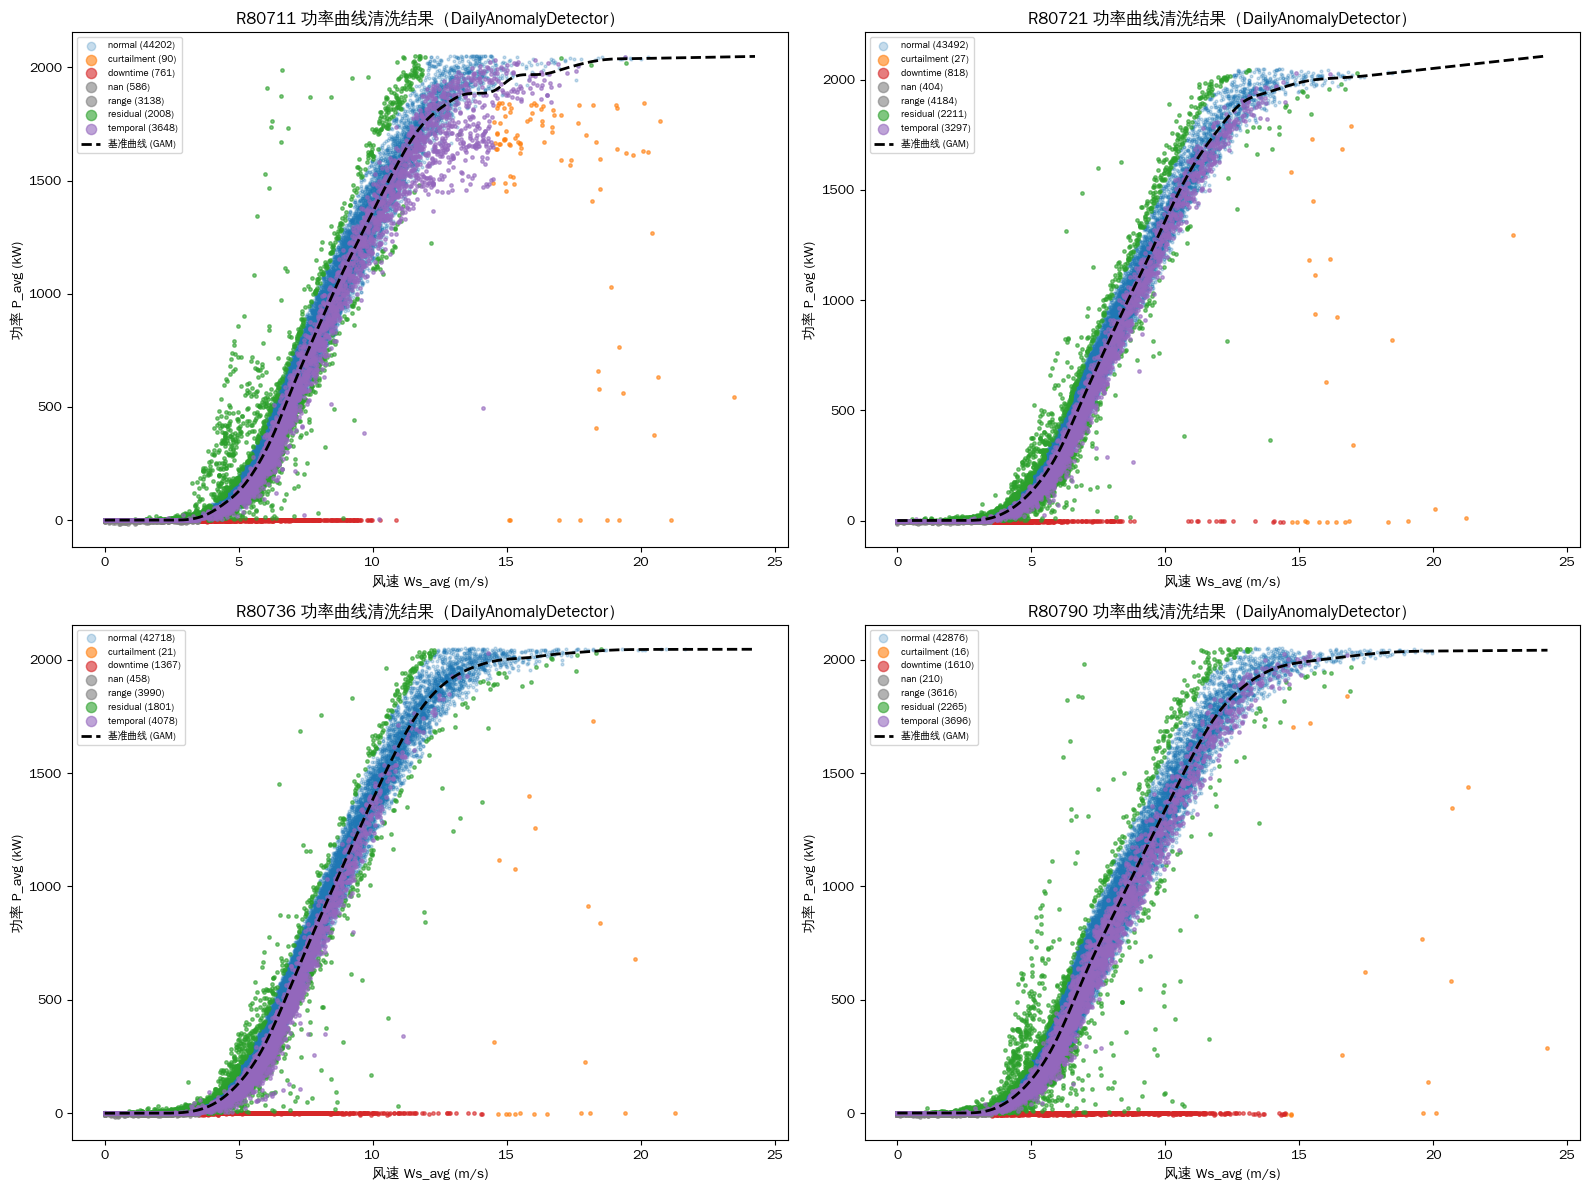

In [8]:
color_map = {
    'normal': 'tab:blue',
    'curtailment': 'tab:orange',
    'downtime': 'tab:red',
    'temporal': 'tab:purple',
    'residual': 'tab:green',
    'range': 'tab:gray',
    'nan': 'tab:gray',
}

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for ax, name in zip(axes.ravel(), turbines):
    r = results[name]
    det = r['det']
    normal_df = r['normal_df']
    abnormal_df = r['abnormal_df']

    ab = abnormal_df.copy()
    ab['_type'] = det.labels_[ab.index]

    ax.scatter(normal_df['Ws_avg'], normal_df['P_avg'], s=4, alpha=0.25,
               c=color_map['normal'], label=f'normal ({len(normal_df)})')

    for typ, sub in ab.groupby('_type'):
        ax.scatter(sub['Ws_avg'], sub['P_avg'], s=6, alpha=0.6,
                   c=color_map.get(typ, 'tab:pink'), label=f'{typ} ({len(sub)})')

    ws_grid = np.linspace(df['Ws_avg'].min(), df['Ws_avg'].max(), 200)
    ax.plot(ws_grid, det.base_curve_(ws_grid), 'k--', linewidth=2, label='基准曲线 (GAM)')

    ax.set_xlabel('风速 Ws_avg (m/s)')
    ax.set_ylabel('功率 P_avg (kW)')
    ax.set_title(f'{name} 功率曲线清洗结果（DailyAnomalyDetector）')
    ax.legend(markerscale=3, fontsize=7)

plt.tight_layout()
plt.show()
